# Descriptive Statistics

Side-by-side overview of **Batch 1** (2023 cohort) and **Batch 2** (2024 cohort). All tables are generated from the preprocessed CSVs via `DatasetLoader`; re-running preprocessing automatically refreshes every figure.

## Setup

In [1]:
import os
os.chdir('/home/adam/personal/msc/thesis/Data and code')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from adamthesis.data_loading import DatasetLoader
from adamthesis.data_labels import (
    twq_sections, raw_grade_mapping,
    old_prereqs, new_prereqs,
)

b1_ind = DatasetLoader().use_batch1_individual_data_csv().df
b2_ind = DatasetLoader().use_batch2_individual_data_csv().df
b1_grp = DatasetLoader().use_batch1_group_data_csv().df
b2_grp = DatasetLoader().use_batch2_group_data_csv().df

# Combined datasets: concatenate both batches
comb_ind = pd.concat([b1_ind, b2_ind], ignore_index=True)
# For group-level combined stats, tag team IDs to avoid ID collisions
comb_grp = pd.concat([b1_grp, b2_grp], ignore_index=True)

GENDER_LABELS  = {0: 'Male', 1: 'Female'}
INTL_LABELS    = {0: 'Turkish', 1: 'International'}
GRADE_FROM_NUM = {v: k for k, v in raw_grade_mapping.items()}
GRADE_FROM_NUM[-1] = 'Not taken'

_ID_COLS  = ['Team ID', 'student Id']
_TGT_COLS = ['491_success', '492_success']

FIGURE_SAVING_PATH = "notebooks/figures"


def side_by_side(b1, b2, b3=None, names=None):
    """Concatenate two or three Series/DataFrames as labelled parallel columns."""
    if names is None:
        names = ('Batch 1', 'Batch 2', 'Combined') if b3 is not None else ('Batch 1', 'Batch 2')
    items = [b1, b2] if b3 is None else [b1, b2, b3]
    if isinstance(b1, pd.Series):
        return pd.concat([s.rename(n) for s, n in zip(items, names)], axis=1)
    copies = []
    for df, name in zip(items, names):
        d = df.copy()
        d.columns = pd.MultiIndex.from_product([[name], d.columns])
        copies.append(d)
    return pd.concat(copies, axis=1)


print("Data loaded. Batch 1 individual shape:", b1_ind.shape,
      "  Batch 2 individual shape:", b2_ind.shape,
      "  Combined individual shape:", comb_ind.shape)
print("Batch 1 group shape:", b1_grp.shape,
      "  Batch 2 group shape:", b2_grp.shape,
      "  Combined group shape:", comb_grp.shape)


Data loaded. Batch 1 individual shape: (50, 61)   Batch 2 individual shape: (50, 73)   Combined individual shape: (100, 73)
Batch 1 group shape: (13, 56)   Batch 2 group shape: (13, 68)   Combined group shape: (26, 68)


## 1  Overview

In [2]:
def _n_features(df):
    return len([c for c in df.columns if c not in _ID_COLS + _TGT_COLS])

b1_courses   = [c for c in b1_ind.columns if c.isdigit()]
b2_courses   = [c for c in b2_ind.columns if c.isdigit()]
comb_courses = sorted(set(b1_courses) | set(b2_courses), key=int)

overview = pd.DataFrame({
    'Batch 1': [
        len(b1_ind),
        b1_ind['Team ID'].nunique(),
        round(len(b1_ind) / b1_ind['Team ID'].nunique(), 1),
        _n_features(b1_ind),
        len(b1_courses),
        int(b1_ind['491_success'].sum()),
        f"{b1_ind['491_success'].mean()*100:.1f}%",
        int(b1_ind['492_success'].sum()),
        f"{b1_ind['492_success'].mean()*100:.1f}%",
    ],
    'Batch 2': [
        len(b2_ind),
        b2_ind['Team ID'].nunique(),
        round(len(b2_ind) / b2_ind['Team ID'].nunique(), 1),
        _n_features(b2_ind),
        len(b2_courses),
        int(b2_ind['491_success'].sum()),
        f"{b2_ind['491_success'].mean()*100:.1f}%",
        int(b2_ind['492_success'].sum()),
        f"{b2_ind['492_success'].mean()*100:.1f}%",
    ],
    'Combined': [
        len(comb_ind),
        comb_ind['Team ID'].nunique(),
        round(len(comb_ind) / comb_ind['Team ID'].nunique(), 1),
        '—',
        len(comb_courses),
        int(comb_ind['491_success'].sum()),
        f"{comb_ind['491_success'].mean()*100:.1f}%",
        int(comb_ind['492_success'].sum()),
        f"{comb_ind['492_success'].mean()*100:.1f}%",
    ],
}, index=[
    'Students', 'Teams', 'Mean students / team',
    'Feature columns (excl. targets)', 'Course-grade columns',
    '491_success  — AA count', '491_success  — AA rate',
    '492_success  — AA count', '492_success  — AA rate',
])
overview


,Batch 1,Batch 2,Combined
Students,50,50,100
Teams,13,13,26
Mean students / team,3.8,3.8,3.8
Feature columns (excl. targets),57,69,—
Course-grade columns,23,29,29
491_success — AA count,26,20,46
491_success — AA rate,52.0%,40.0%,46.0%
492_success — AA count,26,28,54
492_success — AA rate,52.0%,56.0%,54.0%


## 2  Target Balance

In [3]:
def _target_table(df):
    rows = []
    for tgt in ['491_success', '492_success']:
        vc = df[tgt].value_counts().sort_index()
        n  = len(df)
        for label, val in [('Fail (0)', 0), ('Pass (1)', 1)]:
            rows.append({'Target': tgt, 'Class': label,
                         'Count': int(vc.get(val, 0)),
                         '%': f"{100*vc.get(val,0)/n:.1f}%"})
    return pd.DataFrame(rows).set_index(['Target', 'Class'])

side_by_side(_target_table(b1_ind), _target_table(b2_ind), _target_table(comb_ind))


Batch 1        Batch 2        Combined       
                       Count      %   Count      %    Count      %
Target      Class                                                 
491_success Fail (0)      24  48.0%      30  60.0%       54  54.0%
            Pass (1)      26  52.0%      20  40.0%       46  46.0%
492_success Fail (0)      24  48.0%      22  44.0%       46  46.0%
            Pass (1)      26  52.0%      28  56.0%       54  54.0%

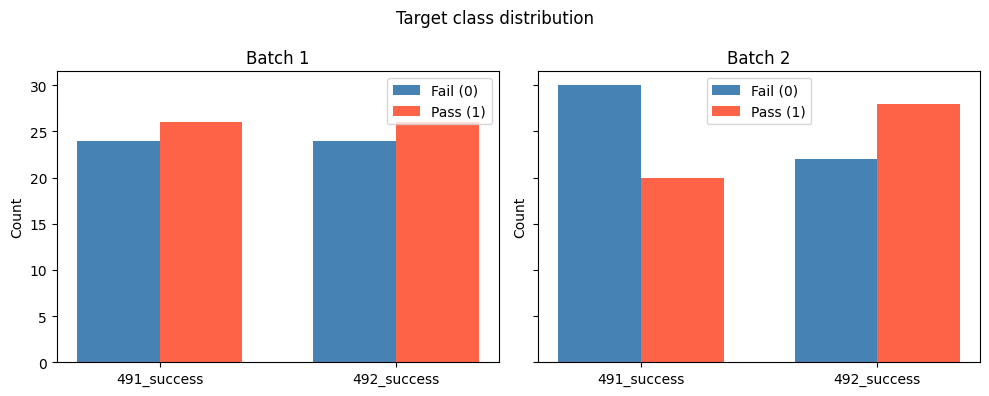

<Figure size 640x480 with 0 Axes>

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, df, title in zip(axes, [b1_ind, b2_ind], ['Batch 1', 'Batch 2']):
    tgts   = ['491_success', '492_success']
    x      = np.arange(len(tgts))
    width  = 0.35
    fails  = [int(df[t].value_counts().get(0, 0)) for t in tgts]
    passes = [int(df[t].value_counts().get(1, 0)) for t in tgts]
    ax.bar(x - width/2, fails,  width, label='Fail (0)', color='steelblue')
    ax.bar(x + width/2, passes, width, label='Pass (1)', color='tomato')
    ax.set_xticks(x); ax.set_xticklabels(tgts)
    ax.set_title(title); ax.set_ylabel('Count'); ax.legend()
plt.suptitle('Target class distribution')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(FIGURE_SAVING_PATH, 'target-class-distribution.png'))

In [5]:
print("Cross-tab 491_success × 492_success")
print("\nBatch 1")
display(pd.crosstab(b1_ind['491_success'], b1_ind['492_success'],
                    rownames=['491_success'], colnames=['492_success'],
                    margins=True))
print("\nBatch 2")
display(pd.crosstab(b2_ind['491_success'], b2_ind['492_success'],
                    rownames=['491_success'], colnames=['492_success'],
                    margins=True))
print("\nCombined")
display(pd.crosstab(comb_ind['491_success'], comb_ind['492_success'],
                    rownames=['491_success'], colnames=['492_success'],
                    margins=True))


Cross-tab 491_success × 492_success

Batch 1


492_success,0,1,All
491_success,,,
0,20,4,24
1,4,22,26
All,24,26,50



Batch 2


492_success,0,1,All
491_success,,,
0,22,8,30
1,0,20,20
All,22,28,50



Combined


492_success,0,1,All
491_success,,,
0,42,12,54
1,4,42,46
All,46,54,100


## 3  Demographics

In [6]:
def _demo_table(df, col, labels):
    vc = df[col].value_counts().sort_index()
    n  = len(df)
    t  = pd.DataFrame({'Count': vc, '%': (vc/n*100).round(1).astype(str)+'%'})
    t.index = t.index.map(labels)
    return t

print("Gender")
display(side_by_side(_demo_table(b1_ind, 'Gender', GENDER_LABELS),
                     _demo_table(b2_ind, 'Gender', GENDER_LABELS),
                     _demo_table(comb_ind, 'Gender', GENDER_LABELS)))

print("\nNationality")
display(side_by_side(_demo_table(b1_ind, 'International', INTL_LABELS),
                     _demo_table(b2_ind, 'International', INTL_LABELS),
                     _demo_table(comb_ind, 'International', INTL_LABELS)))

print("\nLength of Study (semesters in programme — descriptive stats)")
display(side_by_side(b1_ind['Length of Study'].describe().round(2),
                     b2_ind['Length of Study'].describe().round(2),
                     comb_ind['Length of Study'].describe().round(2)))


Gender


Batch 1        Batch 2        Combined       
         Count      %   Count      %    Count      %
Gender                                              
Male        41  82.0%      33  66.0%       74  74.0%
Female       9  18.0%      17  34.0%       26  26.0%


Nationality


Batch 1        Batch 2        Combined       
                Count      %   Count      %    Count      %
International                                              
Turkish            41  82.0%      41  82.0%       82  82.0%
International       9  18.0%       9  18.0%       18  18.0%


Length of Study (semesters in programme — descriptive stats)


,Batch 1,Batch 2,Combined
count,50.00,50.00,100.00
mean,9.10,9.34,9.22
std,1.98,1.67,1.83
min,5.00,8.00,5.00
25%,8.00,8.00,8.00
50%,8.00,9.00,8.00
75%,10.00,10.00,10.00
max,16.00,14.00,16.00


## 4  Academic Features

In [7]:
acad_cols = ['GPA', 'CGPA', '491_SemesterLoad', '492_SemesterLoad']
side_by_side(b1_ind[acad_cols].describe().round(3),
             b2_ind[acad_cols].describe().round(3),
             comb_ind[acad_cols].describe().round(3))


Batch 1                                           Batch 2          \
          GPA    CGPA 491_SemesterLoad 492_SemesterLoad     GPA    CGPA   
count  50.000  50.000           50.000            50.00  50.000  50.000   
mean    2.783   2.741            5.500             5.12   2.704   2.638   
std     0.839   0.490            1.129             1.56   0.881   0.454   
min     0.630   1.810            3.000             1.00   0.690   1.890   
25%     2.250   2.412            5.000             5.00   2.055   2.213   
50%     2.960   2.550            5.000             5.00   2.840   2.620   
75%     3.415   3.098            6.000             6.00   3.438   3.000   
max     3.920   3.940            8.000             7.00   4.000   3.560   

                                        Combined                            \
      491_SemesterLoad 492_SemesterLoad      GPA     CGPA 491_SemesterLoad   
count           50.000           50.000  100.000  100.000          100.000   
mean             5.800            5.440    2.743    2.689            5.650   
std              0.881            1.527    0.857    0.473            1.019   
min              3.000            1.000    0.630    1.810            3.000   
25%              5.000            5.000    2.152    2.320            5.000   
50%              6.000            6.000    2.920    2.590            6.000   
75%              6.000            6.750    3.420    3.062            6.000   
max              7.000            7.000    4.000    3.940            8.000   

                        
      492_SemesterLoad  
count          100.000  
mean             5.280  
std              1.544  
min              1.000  
25%              5.000  
50%              6.000  
75%              6.000  
max              7.000

## 5  Course Grades

Each row is a course.
- **% Taken**: share of students with a recorded grade (i.e. grade ≠ −1).
- **Mean grade**: numeric mean among students who took the course.
- **Modal grade**: most-common letter grade among students who took the course.
- **Prereq (old/new)**: whether the course is on the old (`140,213,350`) or new (`140,213,350,351,242,443`) prerequisite list.

In [8]:
def _course_grade_table(df):
    courses = sorted([c for c in df.columns if c.isdigit()], key=int)
    rows = []
    for c in courses:
        grades     = df[c]
        taken      = grades != -1
        taken_pct  = taken.mean() * 100
        mean_g     = grades[taken].mean() if taken.any() else np.nan
        if taken.any():
            modal_num    = int(grades[taken].mode().iloc[0])
            modal_letter = GRADE_FROM_NUM.get(modal_num, str(modal_num))
        else:
            modal_letter = 'N/A'
        rows.append({
            'Course':            c,
            '% Taken':           f"{taken_pct:.1f}%",
            'Mean grade':        round(mean_g, 2) if not np.isnan(mean_g) else '—',
            'Modal grade':       modal_letter,
            'Prereq (old)':      '✓' if c in old_prereqs else '',
            'Prereq (new)':      '✓' if c in new_prereqs else '',
        })
    return pd.DataFrame(rows).set_index('Course')


def _course_grade_table_combined(df1, df2):
    """Course grade table for the union of courses across two DataFrames."""
    courses = sorted(set(
        [c for c in df1.columns if c.isdigit()] +
        [c for c in df2.columns if c.isdigit()]
    ), key=int)
    # Build a combined frame filling missing course columns with -1
    df = pd.concat([
        df1.reindex(columns=df1.columns.tolist() + [c for c in courses if c not in df1.columns]).fillna({c: -1 for c in courses}),
        df2.reindex(columns=df2.columns.tolist() + [c for c in courses if c not in df2.columns]).fillna({c: -1 for c in courses}),
    ], ignore_index=True)
    rows = []
    for c in courses:
        grades     = df[c]
        taken      = grades != -1
        taken_pct  = taken.mean() * 100
        mean_g     = grades[taken].mean() if taken.any() else np.nan
        if taken.any():
            modal_num    = int(grades[taken].mode().iloc[0])
            modal_letter = GRADE_FROM_NUM.get(modal_num, str(modal_num))
        else:
            modal_letter = 'N/A'
        rows.append({
            'Course':       c,
            '% Taken':      f"{taken_pct:.1f}%",
            'Mean grade':   round(mean_g, 2) if not np.isnan(mean_g) else '—',
            'Modal grade':  modal_letter,
            'Prereq (old)': '✓' if c in old_prereqs else '',
            'Prereq (new)': '✓' if c in new_prereqs else '',
        })
    return pd.DataFrame(rows).set_index('Course')


print("Batch 1 — Course grades (grade columns present in batch1)")
display(_course_grade_table(b1_ind))
print("\nBatch 2 — Course grades (grade columns present in batch2)")
display(_course_grade_table(b2_ind))
print("\nCombined — Course grades (union of courses from both batches)")
display(_course_grade_table_combined(b1_ind, b2_ind))


Batch 1 — Course grades (grade columns present in batch1)


,% Taken,Mean grade,Modal grade,Prereq (old),Prereq (new)
Course,,,,,
140,100.0%,7.58,AA,✓,✓
213,100.0%,6.68,CC,✓,✓
242,100.0%,6.64,CC,,✓
350,100.0%,6.30,CC,✓,✓
351,100.0%,6.54,BB,,✓
352,64.0%,7.69,BB,,
371,16.0%,9.12,AA,,
409,34.0%,6.88,CC,,
436,42.0%,7.14,BB,,



Batch 2 — Course grades (grade columns present in batch2)


,% Taken,Mean grade,Modal grade,Prereq (old),Prereq (new)
Course,,,,,
140,100.0%,7.88,BA,✓,✓
213,100.0%,6.68,DC,✓,✓
242,98.0%,6.2,CC,,✓
350,100.0%,6.58,CC,✓,✓
351,100.0%,6.6,CC,,✓
352,56.0%,6.89,BB,,
353,38.0%,6.84,BA,,
371,0.0%,—,N/A,,
403,36.0%,6.56,CC,,



Combined — Course grades (union of courses from both batches)


,% Taken,Mean grade,Modal grade,Prereq (old),Prereq (new)
Course,,,,,
140,100.0%,7.73,BA,✓,✓
213,100.0%,6.68,CC,✓,✓
242,99.0%,6.42,CC,,✓
350,100.0%,6.44,CC,✓,✓
351,100.0%,6.57,DD,,✓
352,60.0%,7.32,BB,,
353,19.0%,6.84,BA,,
371,8.0%,9.12,AA,,
403,18.0%,6.56,CC,,


## 6  Course Relevancy

For each `<course>_Relevancy` column, the share of students who marked the course as relevant to CNG491/492.

In [9]:
def _relevancy_table(df):
    rel_cols = sorted(
        [c for c in df.columns if c.endswith('_Relevancy')],
        key=lambda c: int(c.replace('_Relevancy', ''))
    )
    rows = []
    for c in rel_cols:
        course = c.replace('_Relevancy', '')
        count  = int((df[c] == 1).sum())
        rows.append({'Course': course,
                     'Count relevant': count,
                     '% Relevant': f"{100*count/len(df):.1f}%"})
    return pd.DataFrame(rows).set_index('Course')


def _relevancy_table_combined(df1, df2):
    """Relevancy table for the union of courses across two DataFrames."""
    all_rel = sorted(
        set(
            [c for c in df1.columns if c.endswith('_Relevancy')] +
            [c for c in df2.columns if c.endswith('_Relevancy')]
        ),
        key=lambda c: int(c.replace('_Relevancy', ''))
    )
    n_total = len(df1) + len(df2)
    rows = []
    for c in all_rel:
        course = c.replace('_Relevancy', '')
        count  = int((df1[c] == 1).sum() if c in df1.columns else 0) + \
                 int((df2[c] == 1).sum() if c in df2.columns else 0)
        rows.append({'Course': course,
                     'Count relevant': count,
                     '% Relevant': f"{100*count/n_total:.1f}%"})
    return pd.DataFrame(rows).set_index('Course')


print("Batch 1 — Course relevancy")
display(_relevancy_table(b1_ind))
print("\nBatch 2 — Course relevancy")
display(_relevancy_table(b2_ind))
print("\nCombined — Course relevancy (union of courses)")
display(_relevancy_table_combined(b1_ind, b2_ind))


Batch 1 — Course relevancy


,Count relevant,% Relevant
Course,,
352,31,62.0%
371,0,0.0%
409,31,62.0%
436,4,8.0%
438,4,8.0%
443,8,16.0%
445,27,54.0%
457,0,0.0%
462,39,78.0%



Batch 2 — Course relevancy


,Count relevant,% Relevant
Course,,
352,8,16.0%
353,0,0.0%
371,0,0.0%
403,12,24.0%
409,34,68.0%
414,0,0.0%
436,12,24.0%
438,0,0.0%
443,4,8.0%



Combined — Course relevancy (union of courses)


,Count relevant,% Relevant
Course,,
352,39,39.0%
353,0,0.0%
371,0,0.0%
403,12,12.0%
409,65,65.0%
414,0,0.0%
436,16,16.0%
438,4,4.0%
443,12,12.0%


## 7  Teamwork Quality (TWQ) Section Distributions

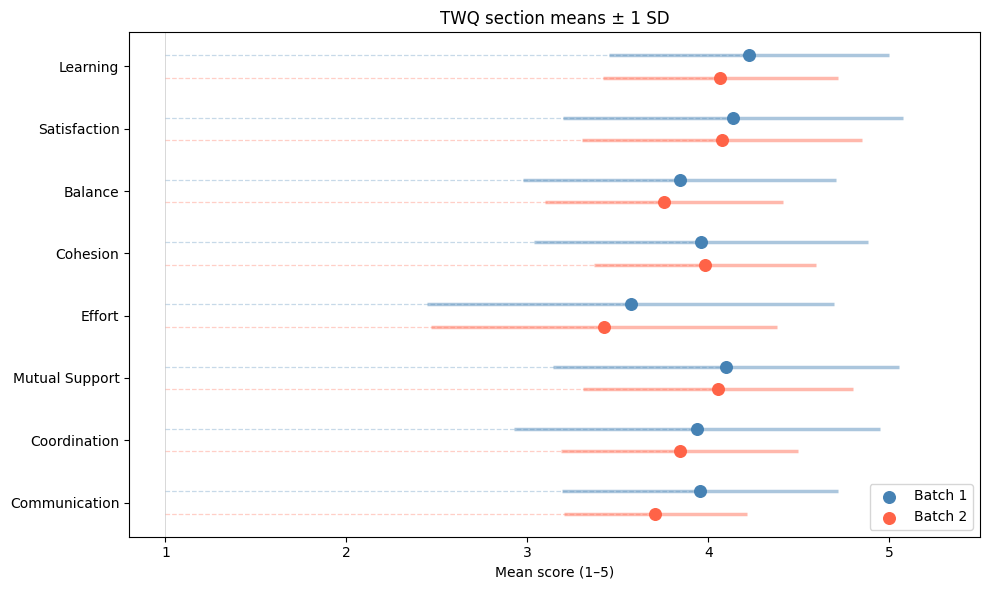

In [10]:
y      = np.arange(len(twq_sections))
offset = 0.18

fig, ax = plt.subplots(figsize=(10, 6))

for df, label, color, yo in [
        (b1_ind, "Batch 1", "steelblue", +offset),
        (b2_ind, "Batch 2", "tomato",    -offset),
]:
    means = df[twq_sections].mean()
    stds  = df[twq_sections].std()
    yi    = y + yo
    # SD range bar
    ax.hlines(yi, means - stds, means + stds,
              color=color, linewidth=2.5, alpha=0.45)
    # stem from scale origin (1) to mean
    ax.hlines(yi, 1, means,
              color=color, linewidth=0.9, alpha=0.3, linestyle="--")
    # dot
    ax.scatter(means, yi, color=color, s=70, zorder=4, label=label)

ax.set_yticks(y)
ax.set_yticklabels(twq_sections)
ax.set_xlabel("Mean score (1–5)")
ax.set_xlim(0.8, 5.5)
ax.axvline(x=1, color="grey", linewidth=0.6, alpha=0.35)
ax.set_title("TWQ section means ± 1 SD")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_SAVING_PATH, "twq-lollipop.png"), dpi=150)
plt.show()


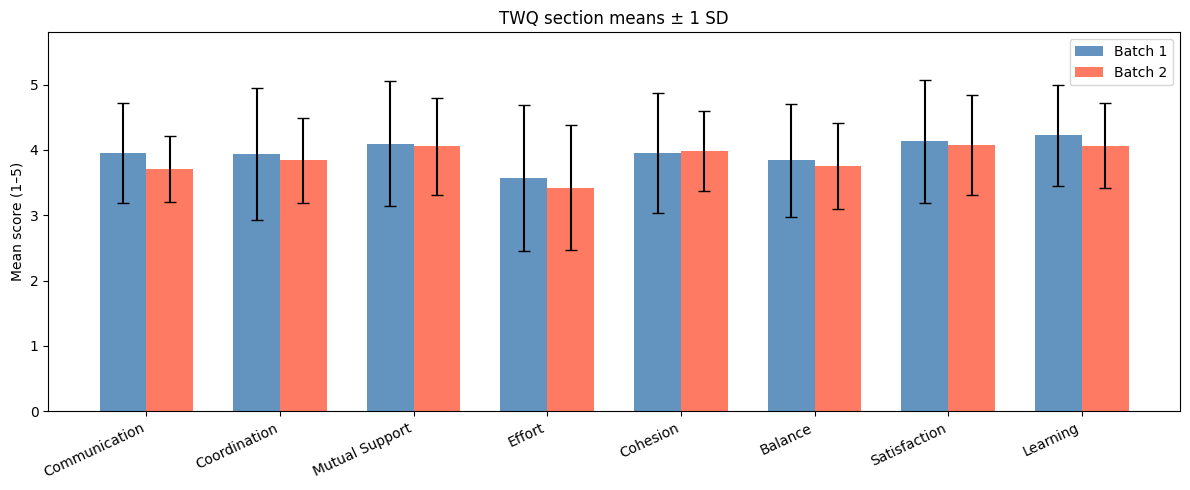

In [11]:
x      = np.arange(len(twq_sections))
width  = 0.35
b1_m   = b1_ind[twq_sections].mean()
b2_m   = b2_ind[twq_sections].mean()
b1_s   = b1_ind[twq_sections].std()
b2_s   = b2_ind[twq_sections].std()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width/2, b1_m, width, yerr=b1_s, label='Batch 1',
       color='steelblue', capsize=4, alpha=0.85)
ax.bar(x + width/2, b2_m, width, yerr=b2_s, label='Batch 2',
       color='tomato',    capsize=4, alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(twq_sections, rotation=25, ha='right')
ax.set_ylabel('Mean score (1–5)')
ax.set_ylim(0, 5.8)
ax.set_title('TWQ section means ± 1 SD')
ax.legend()
plt.tight_layout()
plt.show()

## 8  Group-Level Data

In [12]:
# Team size distribution
# Tag team IDs with batch prefix to prevent cross-batch ID collisions
b1_tagged = b1_ind.assign(**{'Team ID': b1_ind['Team ID'].astype(str) + '_b1'})
b2_tagged = b2_ind.assign(**{'Team ID': b2_ind['Team ID'].astype(str) + '_b2'})
comb_tagged = pd.concat([b1_tagged, b2_tagged], ignore_index=True)

b1_sizes   = b1_ind.groupby('Team ID').size().value_counts().sort_index().rename('Count')
b2_sizes   = b2_ind.groupby('Team ID').size().value_counts().sort_index().rename('Count')
comb_sizes = comb_tagged.groupby('Team ID').size().value_counts().sort_index().rename('Count')
print("Team size distribution (number of teams with each size)")
display(side_by_side(b1_sizes, b2_sizes, comb_sizes))


Team size distribution (number of teams with each size)


,Batch 1,Batch 2,Combined
3,2.0,NaN,2
4,11.0,12.0,23
2,NaN,1.0,1


In [13]:
# Group GPA / CGPA aggregate
print("Group-level GPA and CGPA")
display(side_by_side(b1_grp[['GPA', 'CGPA']].describe().round(3),
                     b2_grp[['GPA', 'CGPA']].describe().round(3),
                     comb_grp[['GPA', 'CGPA']].describe().round(3)))


Group-level GPA and CGPA


Batch 1         Batch 2         Combined        
          GPA    CGPA     GPA    CGPA      GPA    CGPA
count  13.000  13.000  13.000  13.000   26.000  26.000
mean    2.765   2.739   2.638   2.614    2.702   2.677
std     0.658   0.388   0.694   0.354    0.666   0.369
min     1.323   2.157   1.005   2.010    1.005   2.010
25%     2.505   2.435   2.508   2.460    2.506   2.441
50%     2.810   2.745   2.782   2.590    2.796   2.657
75%     3.140   2.888   2.972   2.808    3.098   2.876
max     3.795   3.455   3.402   3.160    3.795   3.455

In [14]:
# Group-level TWQ
print("Group-level TWQ section means")
display(side_by_side(b1_grp[twq_sections].describe().round(3),
                     b2_grp[twq_sections].describe().round(3),
                     comb_grp[twq_sections].describe().round(3)))


Group-level TWQ section means


Batch 1                                                       \
      Communication Coordination Mutual Support  Effort Cohesion Balance   
count        13.000       13.000         13.000  13.000   13.000  13.000   
mean          3.938        3.918          4.071   3.538    3.937   3.821   
std           0.640        0.836          0.809   0.883    0.774   0.607   
min           2.475        2.188          2.250   1.833    2.225   2.556   
25%           3.775        3.625          3.714   3.250    3.750   3.833   
50%           4.075        4.062          4.357   3.667    4.025   4.000   
75%           4.450        4.417          4.607   4.250    4.525   4.167   
max           4.600        4.875          4.964   4.625    4.850   4.750   

                                  Batch 2               ...               \
      Satisfaction Learning Communication Coordination  ... Satisfaction   
count       13.000   13.000        13.000       13.000  ...       13.000   
mean         4.115    4.223         3.693        3.841  ...        4.053   
std          0.807    0.497         0.294        0.424  ...        0.463   
min          2.250    3.000         3.300        3.062  ...        3.062   
25%          3.812    4.000         3.475        3.625  ...        3.875   
50%          4.250    4.250         3.625        3.875  ...        4.188   
75%          4.750    4.375         3.988        4.062  ...        4.312   
max          4.938    5.000         4.164        4.562  ...        4.812   

                    Combined                                               \
      Learning Communication Coordination Mutual Support  Effort Cohesion   
count   13.000        26.000       26.000         26.000  26.000   26.000   
mean     4.058         3.815        3.880          4.068   3.484    3.957   
std      0.447         0.504        0.651          0.665   0.722    0.600   
min      3.188         2.475        2.188          2.250   1.833    2.225   
25%      3.750         3.494        3.625          3.802   3.125    3.806   
50%      3.938         3.912        3.938          4.261   3.469    4.000   
75%      4.250         4.142        4.297          4.455   4.109    4.319   
max      4.750         4.600        4.875          4.964   4.625    4.850   

                                     
      Balance Satisfaction Learning  
count  26.000       26.000   26.000  
mean    3.772        4.084    4.140  
std     0.514        0.646    0.471  
min     2.556        2.250    3.000  
25%     3.479        3.828    3.891  
50%     3.958        4.188    4.219  
75%     4.153        4.438    4.375  
max     4.750        4.938    5.000  

[8 rows x 24 columns]

In [15]:
# Group-level targets
for tgt in ['491_success', '492_success']:
    b1_vc   = b1_grp[tgt].value_counts().sort_index().rename('Count')
    b2_vc   = b2_grp[tgt].value_counts().sort_index().rename('Count')
    comb_vc = comb_grp[tgt].value_counts().sort_index().rename('Count')
    print(f"\n{tgt}  (group min — team passes only if every member passes)")
    display(side_by_side(b1_vc, b2_vc, comb_vc))



491_success  (group min — team passes only if every member passes)


,Batch 1,Batch 2,Combined
491_success,,,
0,7,8,15
1,6,5,11



492_success  (group min — team passes only if every member passes)


,Batch 1,Batch 2,Combined
492_success,,,
0,7,6,13
1,6,7,13


## 9  Cross-Batch Headline Comparison

Single condensed row per batch for a quick at-a-glance comparison.

In [21]:
def _pct(series):
    return f"{series.mean()*100:.1f}%"

headline = {}
for name, df in [('Batch 1', b1_ind), ('Batch 2', b2_ind), ('Combined', comb_ind)]:
    row = {
        'N students':           len(df),
        'N teams':              df['Team ID'].nunique(),
        '% Female':             _pct(df['Gender']),
        '% International':      _pct(df['International']),
        'Mean length of study': round(df['Length of Study'].mean(), 2),
        '% 491 success':        _pct(df['491_success']),
        '% 492 success':        _pct(df['492_success']),
        'Mean GPA':             round(df['GPA'].mean(), 3),
        'Mean CGPA':            round(df['CGPA'].mean(), 3),
    }
    for sec in twq_sections:
        row[f'Mean TWQ: {sec}'] = round(df[sec].mean(), 3)
    headline[name] = row

pd.DataFrame(headline).rename_axis('Metric')


,Batch 1,Batch 2,Combined
Metric,,,
N students,50,50,100
N teams,13,13,26
% Female,18.0%,34.0%,26.0%
% International,18.0%,18.0%,18.0%
Mean length of study,9.1,9.34,9.22
% 491 success,52.0%,40.0%,46.0%
% 492 success,52.0%,56.0%,54.0%
Mean GPA,2.783,2.704,2.743
Mean CGPA,2.741,2.638,2.689
